#Task_5_Time_Series_Forecasting

**Task 1 – Importing Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

print("All libraries imported successfully!")

All libraries imported successfully!


What these libraries are for
pandas → handling datasets
numpy → numerical calculations
matplotlib → plotting graphs
seasonal_decompose → trend, seasonality, residual analysis
adfuller → stationarity test
ARIMA → forecasting model
MAPE & RMSE → measuring forecast accuracy

**Task 2 – Load the Dataset.**

In [3]:
import pandas as pd

df = pd.read_csv("/content/daily-demand-series.csv")

print(df.head())

         date  demand  marketing_event  holiday
0  2026-06-01     118                0        0
1  2026-06-02     121                0        0
2  2026-06-03     125                0        0
3  2026-06-04     123                0        0
4  2026-06-05     137                1        0


**Task 3 – Check the Dataset**

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
print(df.info())

Dataset Shape: (30, 4)

Column Names:
['date', 'demand', 'marketing_event', 'holiday']

Data Types:
date               object
demand              int64
marketing_event     int64
holiday             int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   date             30 non-null     object
 1   demand           30 non-null     int64 
 2   marketing_event  30 non-null     int64 
 3   holiday          30 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 1.1+ KB
None


**Task 4 – Convert the Date Column**

In [5]:
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date")

df = df.set_index("date")

print(df.head())

            demand  marketing_event  holiday
date                                        
2026-06-01     118                0        0
2026-06-02     121                0        0
2026-06-03     125                0        0
2026-06-04     123                0        0
2026-06-05     137                1        0


**Task 5 – Visualize Daily Demand**

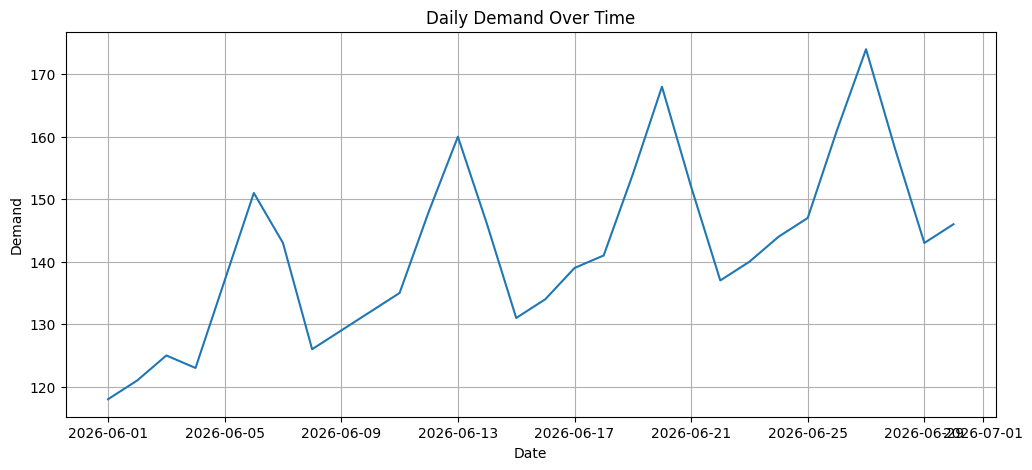

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(df.index, df["demand"])

plt.title("Daily Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.grid(True)

plt.show()

**Task 6 – Time-Series Decomposition**

Now we will separate the demand data into 3 components:
Trend – Long-term increase or decrease in demand.
Seasonality – Repeating patterns.
Residual – Remaining variation that isn't explained by trend or seasonality.

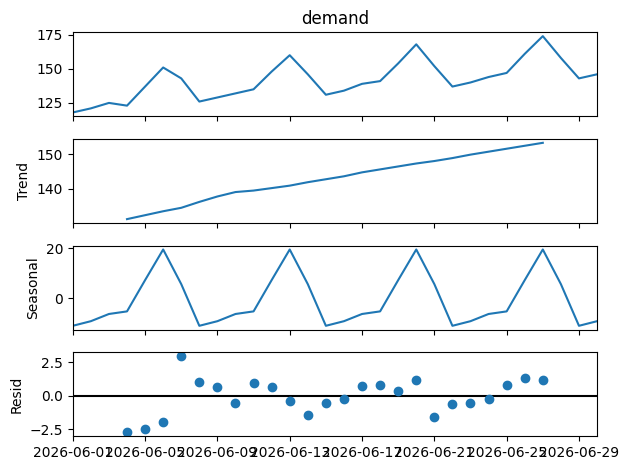

In [7]:
decomposition = seasonal_decompose(
    df["demand"],
    model="additive",
    period=7
)

decomposition.plot()
plt.show()

**Task 7 – Stationarity Test (ADF Test)**

In [8]:
adf_result = adfuller(df["demand"])

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("The data is stationary.")
else:
    print("The data is non-stationary.")

ADF Statistic: -0.9038698873856339
P-value: 0.7866953368372341
The data is non-stationary.


/tmp/ipykernel_3774/4217335071.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df["demand"])


Stationary → data patterns such as mean and variance remain relatively stable over time.
Non-stationary → data patterns change over time.
P-value < 0.05 → stationary.
P-value ≥ 0.05 → non-stationary.

**Task 8 – Differencing the Data**

In [9]:
df["demand_diff"] = df["demand"].diff()

print(df["demand_diff"].head(10))

date
2026-06-01     NaN
2026-06-02     3.0
2026-06-03     4.0
2026-06-04    -2.0
2026-06-05    14.0
2026-06-06    14.0
2026-06-07    -8.0
2026-06-08   -17.0
2026-06-09     3.0
2026-06-10     3.0
Name: demand_diff, dtype: float64


**Task 9 – Check Stationarity Again**

In [10]:
adf_result_diff = adfuller(df["demand_diff"].dropna())

print("ADF Statistic:", adf_result_diff[0])
print("P-value:", adf_result_diff[1])

if adf_result_diff[1] < 0.05:
    print("Differenced data is stationary.")
else:
    print("Differenced data is still non-stationary.")

ADF Statistic: -2.233624012735415
P-value: 0.19426893706635578
Differenced data is still non-stationary.


/tmp/ipykernel_3774/3475843025.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result_diff = adfuller(df["demand_diff"].dropna())


**Task 10 – Split Data into Training and Testing Sets**

Now we will split our demand data into:
Training data (80%) → used to train the forecasting model.
Testing data (20%) → used to evaluate how well the model predicts unseen data.

In [12]:
train_size = int(len(df) * 0.8)

train = df["demand"][:train_size]
test = df["demand"][train_size:]

print("Training Data Size:", len(train))
print("Testing Data Size:", len(test))

Training Data Size: 24
Testing Data Size: 6


**Task 11 – Build the ARIMA Forecasting Model**

In [13]:
model = ARIMA(train, order=(1, 1, 1))

model_fit = model.fit()

print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                 demand   No. Observations:                   24
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 -82.216
Date:                Sat, 28 Nov 2026   AIC                            170.433
Time:                        06:47:22   BIC                            173.839
Sample:                    06-01-2026   HQIC                           171.289
                         - 06-24-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1460      0.380     -0.384      0.701      -0.891       0.599
ma.L1          0.8065      0.182      4.429      0.000       0.450       1.163
sigma2        71.9221     25.311      2.842      0.0

**Task 12 – Forecasting on Test Data**

In [14]:
forecast = model_fit.forecast(steps=len(test))

print("Forecasted Demand:")
print(forecast.head(10))

Forecasted Demand:
2026-06-25    145.071592
2026-06-26    144.915111
2026-06-27    144.937962
2026-06-28    144.934625
2026-06-29    144.935112
2026-06-30    144.935041
Freq: D, Name: predicted_mean, dtype: float64


**Task 13 – Plot Actual vs Predicted Demand**

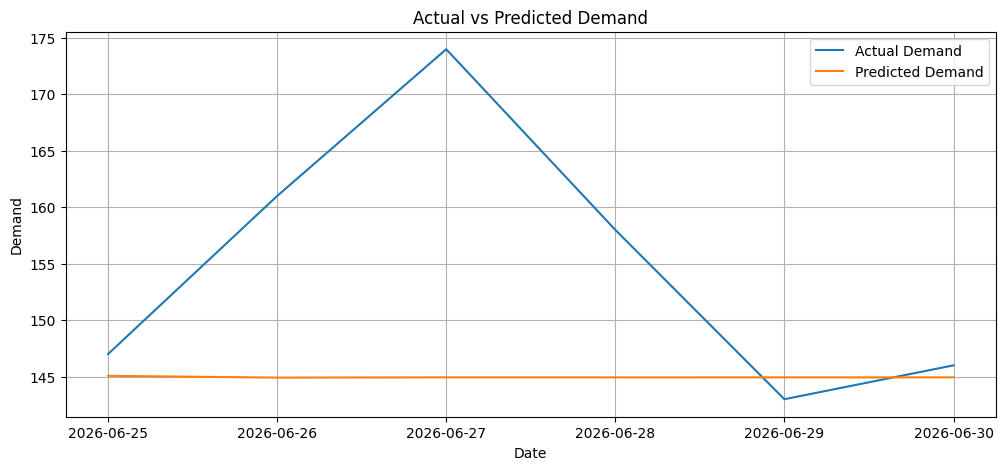

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(test.index, test, label="Actual Demand")
plt.plot(test.index, forecast, label="Predicted Demand")

plt.title("Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)

plt.show()

**Task 14 – Calculate RMSE (Root Mean Squared Error)**

In [16]:
rmse = np.sqrt(mean_squared_error(test, forecast))

print("RMSE:", rmse)

RMSE: 14.620917146995762


**Task 15 – Calculate MAPE**

In [17]:
mape = mean_absolute_percentage_error(test, forecast) * 100

print("MAPE:", mape, "%")

MAPE: 6.392775220077327 %


**Task 16 – Create a 30-Day Future Forecast**

In [18]:
future_forecast = model_fit.forecast(steps=30)

print("Next 30 Days Demand Forecast:")
print(future_forecast)

Next 30 Days Demand Forecast:
2026-06-25    145.071592
2026-06-26    144.915111
2026-06-27    144.937962
2026-06-28    144.934625
2026-06-29    144.935112
2026-06-30    144.935041
2026-07-01    144.935051
2026-07-02    144.935050
2026-07-03    144.935050
2026-07-04    144.935050
2026-07-05    144.935050
2026-07-06    144.935050
2026-07-07    144.935050
2026-07-08    144.935050
2026-07-09    144.935050
2026-07-10    144.935050
2026-07-11    144.935050
2026-07-12    144.935050
2026-07-13    144.935050
2026-07-14    144.935050
2026-07-15    144.935050
2026-07-16    144.935050
2026-07-17    144.935050
2026-07-18    144.935050
2026-07-19    144.935050
2026-07-20    144.935050
2026-07-21    144.935050
2026-07-22    144.935050
2026-07-23    144.935050
2026-07-24    144.935050
Freq: D, Name: predicted_mean, dtype: float64


**Task 17 – Plot the Next 30 Days Forecast**

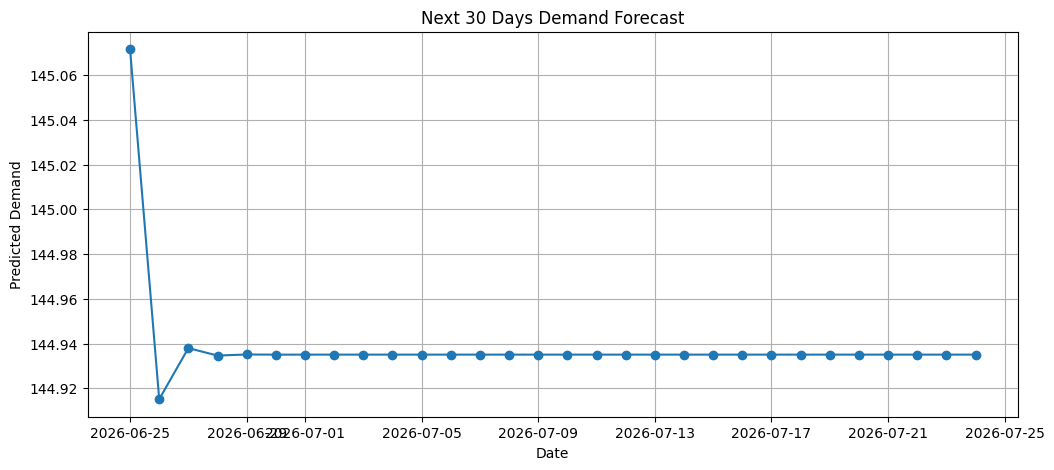

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(future_forecast.index, future_forecast, marker="o")

plt.title("Next 30 Days Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Predicted Demand")

plt.grid(True)
plt.show()

**Task 18 – Final Conclusion**

## Conclusion

In this project, daily demand data was analyzed using time-series analysis techniques. The data was visualized and decomposed into trend, seasonal, and residual components. The Augmented Dickey-Fuller (ADF) test was used to check stationarity, and differencing was applied to help make the data stationary.

An ARIMA model was trained on historical demand data to forecast future demand. Model performance was evaluated using RMSE and MAPE. Finally, a 30-day future demand forecast was generated and visualized.

This project demonstrates the application of time-series analysis and forecasting techniques to predict future demand.